In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("../data/processed/student_placement_cleaned.csv")

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (12000, 13)
   gender  age degree      branch  cgpa  backlogs  internships  \
0    Male   20     BE  Mechanical  8.40         2            2   
1  Female   20  BTech  Electrical  8.60         2            0   
2    Male   22    BCA  Electrical  6.62         3            0   
3    Male   24    BCA          DS  8.01         0            0   
4    Male   24    BCA  Electrical  9.12         2            1   

   certifications  coding_skills  communication_skills  aptitude_score  \
0               2              1                     3              69   
1               5              1                     9              81   
2               1              1                     7              50   
3               4              4                     7              47   
4               2              4                     4              77   

   projects  placed  
0         0       0  
1         4       0  
2         1       0  
3         4       0  
4         4       0  

In [2]:
clustering_features = [
    "age",
    "cgpa",
    "backlogs",
    "internships",
    "certifications",
    "coding_skills",
    "communication_skills",
    "aptitude_score",
    "projects"
]

X_cluster = df[clustering_features]

print("Clustering Features:")
print(clustering_features)
print()
print("Clustering Data Shape:", X_cluster.shape)

Clustering Features:
['age', 'cgpa', 'backlogs', 'internships', 'certifications', 'coding_skills', 'communication_skills', 'aptitude_score', 'projects']

Clustering Data Shape: (12000, 9)


In [4]:
scaler_cluster = StandardScaler()

X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

print("Scaled Data Shape:", X_cluster_scaled.shape)
print("Mean of first feature:", X_cluster_scaled[:, 0].mean())
print("Standard deviation of first feature:", X_cluster_scaled[:, 0].std())

Scaled Data Shape: (12000, 9)
Mean of first feature: 3.552713678800501e-17
Standard deviation of first feature: 1.0


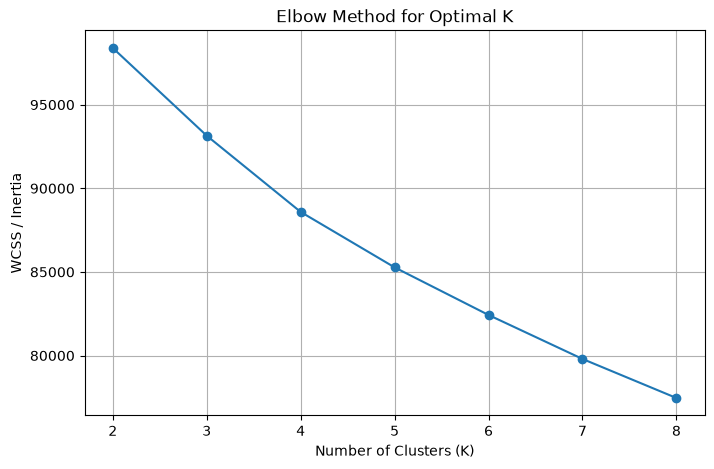

In [5]:
inertia_values = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_cluster_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 9), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(range(2, 9))
plt.grid()
plt.show()

K = 2, Silhouette Score = 0.0888
K = 3, Silhouette Score = 0.0738
K = 4, Silhouette Score = 0.0798
K = 5, Silhouette Score = 0.0756
K = 6, Silhouette Score = 0.0756
K = 7, Silhouette Score = 0.0767
K = 8, Silhouette Score = 0.0782


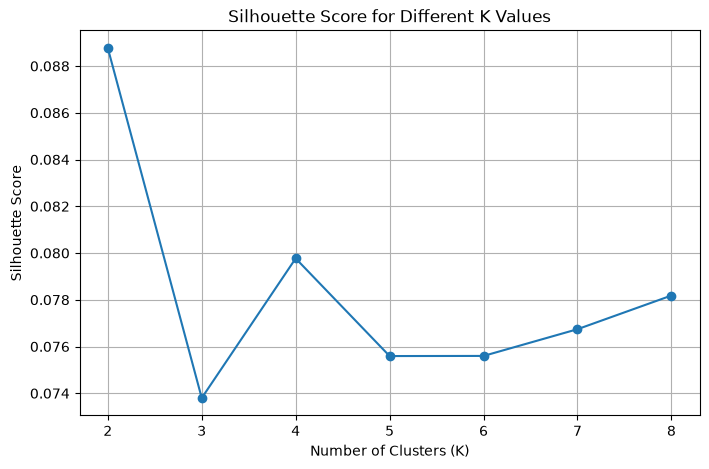

In [6]:
silhouette_scores = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    cluster_labels = kmeans.fit_predict(X_cluster_scaled)
    score = silhouette_score(X_cluster_scaled, cluster_labels)
    silhouette_scores.append(score)
    print(f"K = {k}, Silhouette Score = {score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(2, 9), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(range(2, 9))
plt.grid()
plt.show()

In [7]:
optimal_k = 2

kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_cluster_scaled)

df["cluster"] = cluster_labels

print("K-Means Model Created")
print("Number of Clusters:", optimal_k)
print()
print("Cluster Counts:")
print(df["cluster"].value_counts().sort_index())

K-Means Model Created
Number of Clusters: 2

Cluster Counts:
cluster
0    6043
1    5957
Name: count, dtype: int64


In [8]:
cluster_profile = df.groupby("cluster")[clustering_features].mean().round(2)

print("Cluster Profile:")
print(cluster_profile)

Cluster Profile:
           age  cgpa  backlogs  internships  certifications  coding_skills  \
cluster                                                                      
0        21.98  7.64       0.5         1.51            2.54           5.48   
1        22.00  7.65       2.5         1.49            2.48           5.51   

         communication_skills  aptitude_score  projects  
cluster                                                  
0                         5.5           69.48      2.52  
1                         5.5           69.17      2.49  


In [9]:
cluster_placement = df.groupby("cluster")["placed"].agg(
    ["count", "sum", "mean"]
).round(4)

cluster_placement["placement_rate_%"] = (
    cluster_placement["mean"] * 100
).round(2)

print("Cluster Placement Analysis:")
print(cluster_placement)

Cluster Placement Analysis:
         count   sum    mean  placement_rate_%
cluster                                       
0         6043  1835  0.3037             30.37
1         5957  1817  0.3050             30.50


In [10]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    kmeans_final,
    "../models/kmeans_model.pkl"
)

joblib.dump(
    scaler_cluster,
    "../models/cluster_scaler.pkl"
)

df.to_csv(
    "../data/processed/student_clusters.csv",
    index=False
)

cluster_profile.to_csv(
    "../models/cluster_profiles.csv"
)

cluster_placement.to_csv(
    "../models/cluster_placement.csv"
)

print("CLUSTERING RESULTS SAVED")
print("K-Means Model: ../models/kmeans_model.pkl")
print("Cluster Scaler: ../models/cluster_scaler.pkl")
print("Student Clusters: ../data/processed/student_clusters.csv")
print("Cluster Profiles: ../models/cluster_profiles.csv")
print("Cluster Placement: ../models/cluster_placement.csv")

CLUSTERING RESULTS SAVED
K-Means Model: ../models/kmeans_model.pkl
Cluster Scaler: ../models/cluster_scaler.pkl
Student Clusters: ../data/processed/student_clusters.csv
Cluster Profiles: ../models/cluster_profiles.csv
Cluster Placement: ../models/cluster_placement.csv
